# PRISMA: hGRS versions compared

This notebook compares the L2A products of hGRS 1.1.2, 1.2.0.dev0 and 2.0.0 on the same PRISMA image, the
acquisition of 2026-02-06 over three islands of the South Atlantic coast of Brazil (39.3-38.95° W,
18.15-17.8° S), with strong sunglint and clear offshore water (the image of the tutorial
[PRISMA: from L1 to the hGRS L2A product](prisma_l1_l2a.ipynb)). All three products were processed from the
same L1 and L2C files and the same CAMS forecast, with the default settings of each version (2.0.0: branch
`feature/abs_scat_coupling`, commit f438100, whose changes since 2.0.0 leave the default products unchanged).

The main changes between the versions (see the [history](../history.rst)):

* **1.2.0.dev0** (development version before 1.2.0): validity and cloud masks, smoothing of the water vapor and aerosol retrievals, aerosol solver;
* **2.0.0**: coupling of the gaseous absorption with the scattering in the O2 and H2O windows of 684-990 nm
  (`gas_coupling: path_length`), line-by-line O2 in the O2-B band (`o2_model: lbl_o2b`) and a water vapor
  fit over 931-1060 nm (was 800-1300 nm).

Over clear water $R_{rs}$ is smooth in the red and near infrared: any narrow peak or dip at the wavelengths of
the gaseous absorption bands is a residual of the gaseous correction. The comparison looks at the
retrieved parameters, $R_{rs}$ of clear water, the residual depth of the absorption bands, and the effect of
the two new options of 2.0.0, isolated by processing the image again with each of them switched back.

## Setup

In [1]:
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams['figure.dpi'] = 90

### Input files

The products of each version, and two products of 2.0.0 processed with one option set back to its value of
1.2.0.dev0 (user configuration file given by the `HGRS_CONFIG` environment variable, see
[Configuration](../configuration.rst)):

* `2.0.0, decoupled`: `atmospheric_correction: product: gas_coupling: decoupled` (direct-beam gaseous
  transmittance for the whole signal, as in 1.2.0.dev0);
* `2.0.0, o2 lbl`: `o2_model: lbl` (line-by-line O2 in the O2-A band too, REPTRAN by default).

In [2]:
root = '/data/satellite/prisma/l2a-hgrs'
acquisition = '20260206130152_20260206130157_0001'
cams_file = '/data/cams/world/2026/02/06/2026-02-06-cams-global-atmospheric-composition-forecasts.nc'

files = {'1.1.2': f'{root}/v1.1.2/2026/02/06/PRS_L2A_hgrs_{acquisition}_V1.1.2.nc',
         '1.2.0.dev0': f'{root}/v1.2.0dev0/2026/02/06/PRS_L2A_hgrs_{acquisition}_V1.2.0dev0.nc',
         '2.0.0': f'{root}/v2.0.0/2026/02/06/PRS_L2A_hgrs_{acquisition}_V2.0.0.nc'}
diagnostics = {'2.0.0, decoupled': f'{root}/v2.0.0_decoupled/2026/02/06/PRS_L2A_hgrs_{acquisition}_V2.0.0.nc',
               '2.0.0, o2 lbl': f'{root}/v2.0.0_o2lbl/2026/02/06/PRS_L2A_hgrs_{acquisition}_V2.0.0.nc'}
colors = {'1.1.2': 'tab:gray', '1.2.0.dev0': 'tab:blue', '2.0.0': 'tab:red',
          '2.0.0, decoupled': 'tab:orange', '2.0.0, o2 lbl': 'tab:green'}

products = {name: xr.open_dataset(path).sortby('y') for name, path in {**files, **diagnostics}.items()}

## 1. Retrieved parameters

Median over the mega-pixels of the aerosol optical thickness at 550 nm, the water vapor column and the
sunglint amplitude, against the CAMS forecast at the image (nearest grid point, mean of the forecast
steps of the day).

In [3]:
cams = xr.open_dataset(cams_file).sel(latitude=-18, longitude=360 - 39.1, method='nearest')
print(f"CAMS: AOT(550) {float(cams.aod550.mean()):.3f}, water vapor {float(cams.tcwv.mean()):.1f} kg m-2")

summary = pd.DataFrame({name: {'aerosol model': ds.attrs['aerosol_model'],
                               'AOT(550)': float(ds.aot_ref_smoothed.median()),
                               'water vapor (kg m-2)': float(ds.tcwv.median()),
                               'sunglint': float(ds.brdfg.median()),
                               'water vapor range (nm)': ds.attrs['wl_water_vapor']}
                        for name, ds in products.items()}).T
summary

CAMS: AOT(550) 0.064, water vapor 32.7 kg m-2


,aerosol model,AOT(550),water vapor (kg m-2),sunglint,water vapor range (nm)
1.1.2,ARCT_rh70,0.137727,23.33,0.087755,"slice(800, 1300, None)"
1.2.0.dev0,ARCT_rh70,0.096387,22.17,0.086925,"slice(800, 1300, None)"
2.0.0,ARCT_rh70,0.089083,26.96,0.0889,"slice(931, 1060, None)"
"2.0.0, decoupled",ARCT_rh70,0.146786,26.43,0.08706,"slice(931, 1060, None)"
"2.0.0, o2 lbl",ARCT_rh70,0.154326,26.96,0.08728,"slice(931, 1060, None)"


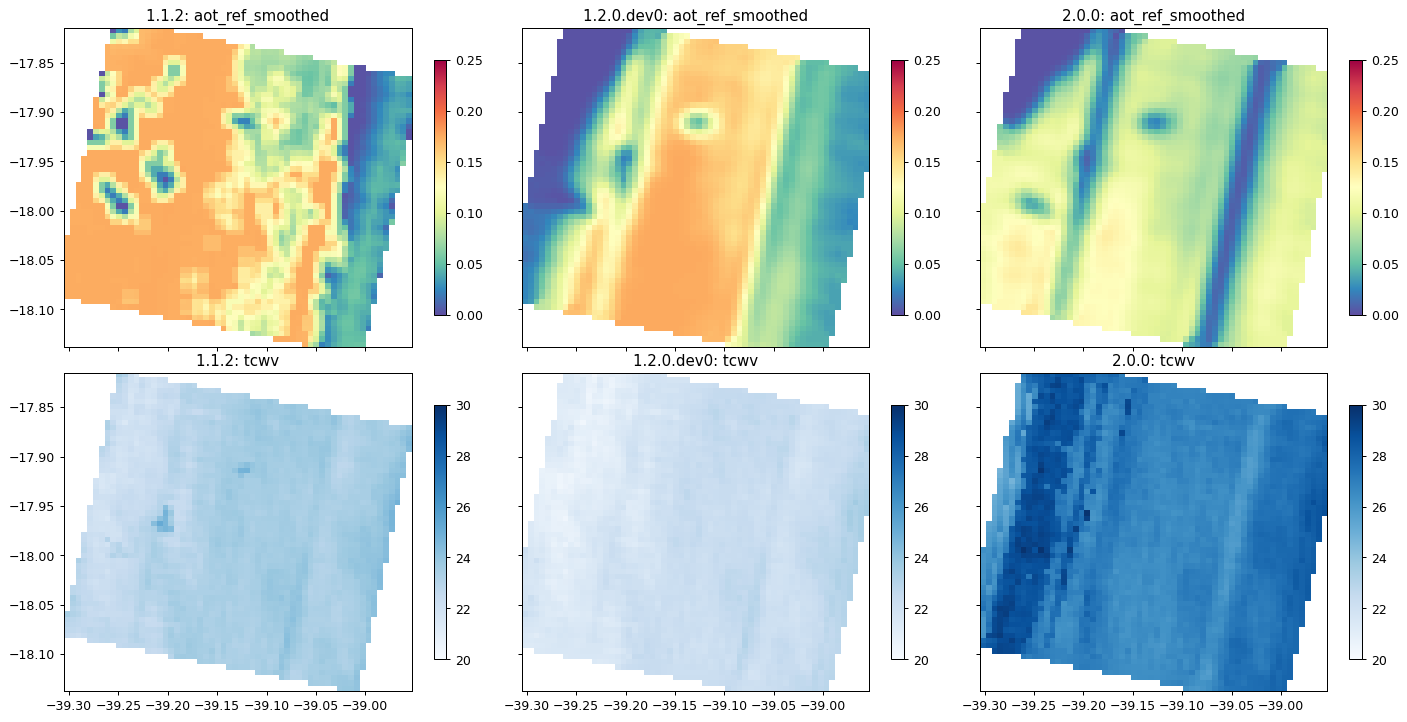

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=True)
for col, name in enumerate(files):
    ds = products[name]
    for row, (param, cmap, vmin, vmax) in enumerate([('aot_ref_smoothed', 'Spectral_r', 0, 0.25),
                                                      ('tcwv', 'Blues', 20, 30)]):
        ds[param].plot.imshow(ax=axs[row, col], x='xc', y='yc', cmap=cmap, vmin=vmin, vmax=vmax,
                              cbar_kwargs={'label': '', 'shrink': 0.8})
        axs[row, col].set(title=f'{name}: {param}', xlabel='', ylabel='', aspect='equal')
plt.tight_layout()

## 2. $R_{rs}$ of clear water

Median $R_{rs}$ of the offshore water east of the islands (39.05-38.97° W, 17.96-17.88° S), where the
water is clear and deep.

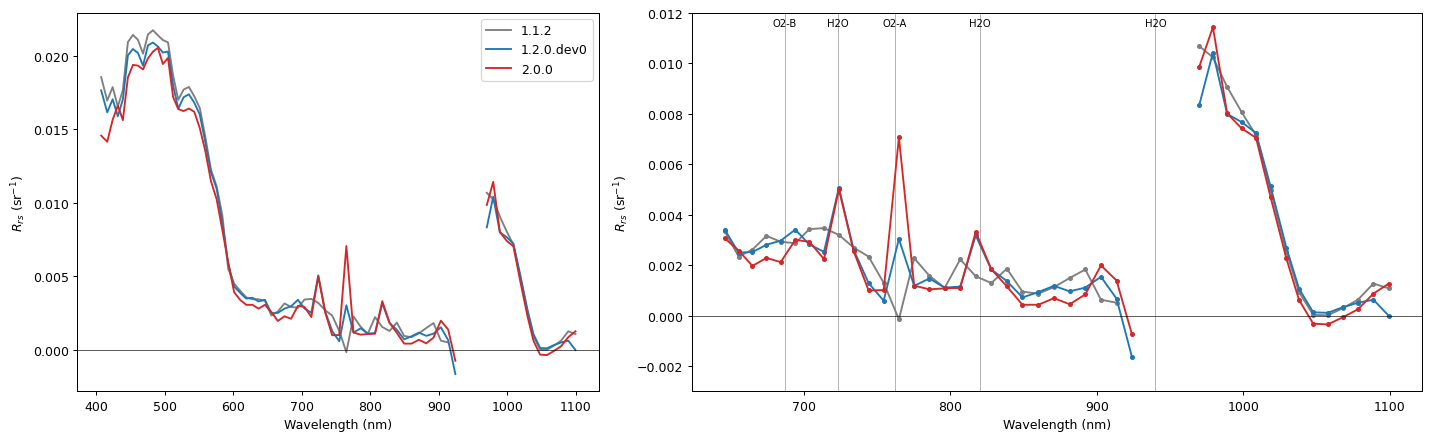

In [5]:
offshore = dict(x=slice(-39.05, -38.97), y=slice(-17.96, -17.88))
spectra = {name: ds.Rrs.sel(**offshore).median(['x', 'y']).compute() for name, ds in products.items()}
gas_bands = {'O2-B': 687, 'H2O': 723, 'O2-A': 762, 'H2O ': 820, 'H2O  ': 940}

fig, axs = plt.subplots(1, 2, figsize=(16, 5), width_ratios=[1, 1.4])
for name in files:
    spectra[name].plot(ax=axs[0], color=colors[name], label=name)
    spectra[name].sel(wl=slice(640, 1100)).plot(ax=axs[1], color=colors[name], marker='.', label=name)
for label, wl in gas_bands.items():
    axs[1].axvline(wl, color='0.7', lw=0.8, zorder=0)
    axs[1].text(wl, 0.0115, label.strip(), ha='center', fontsize=8)
for ax in axs:
    ax.axhline(0, color='k', lw=0.5)
    ax.set(xlabel='Wavelength (nm)', ylabel='$R_{rs}$ (sr$^{-1}$)', title='')
axs[1].set_ylim(-0.003, 0.012)
axs[0].legend()
plt.tight_layout()

## 3. Residual depth of the absorption bands

For each band, $R_{rs}$ of the band (mean of the PRISMA bands inside it) minus the straight line between
two bands of its shoulders, median over the water pixels: 0 when the gaseous correction leaves no trace,
positive for an overcorrection (peak), negative for an undercorrection (dip). Over clear water, where
$R_{rs}$ is close to 0 beyond 700 nm, the line is a good estimate of the true $R_{rs}$; in the turbid water
near the islands it is only approximate.

In [6]:
features = {'O2-B 687': ([684.1, 694.1], [674.5, 703.7]),
            'H2O 720': ([723.9, 733.9], [703.7, 744.1]),
            'O2-A 762': ([764.9], [744.1, 785.7]),
            'H2O 820': ([817.3, 827.9], [796.1, 849.2]),
            'H2O 940': ([923.9, 934.1], [881.5, 1008.6])}


def band_residual(rrs, center, shoulders):
    '''R_rs of the band minus the line between its shoulders.'''
    cen = rrs.sel(wl=center, method='nearest')
    sh = rrs.sel(wl=shoulders, method='nearest')
    slope = (sh.isel(wl=1) - sh.isel(wl=0)) / (sh.wl[1] - sh.wl[0])
    return (cen - (sh.isel(wl=0) + slope * (cen.wl - sh.wl[0]))).mean('wl')


rows = {}
for name, ds in products.items():
    for area, sel in {'offshore': offshore, 'all water': {}}.items():
        rrs = ds.Rrs.sel(**sel).isel(x=slice(None, None, 3), y=slice(None, None, 3)).compute()
        rows[(name, area)] = {feature: float(band_residual(rrs, *bands).median())
                              for feature, bands in features.items()}
residuals = pd.DataFrame(rows).T * 1e4
residuals.style.format('{:+.1f}', na_rep='-').set_caption('residual band depth (1e-4 sr-1)')

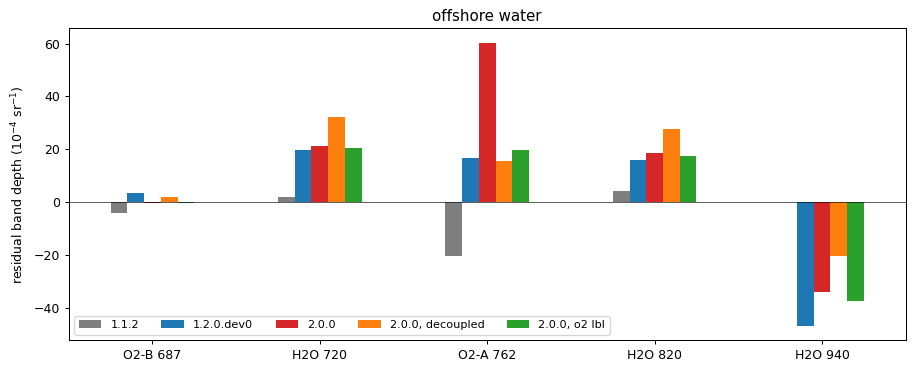

In [7]:
ax = residuals.xs('offshore', level=1).T.plot.bar(figsize=(12, 4.5), rot=0,
                                                   color=[colors[name] for name in products])
ax.axhline(0, color='k', lw=0.5)
ax.set(ylabel='residual band depth (10$^{-4}$ sr$^{-1}$)', title='offshore water')
ax.legend(ncol=5, fontsize=9);

## 4. The new options of 2.0.0, one at a time

$R_{rs}$ of the offshore water in the red and near infrared, for 2.0.0 and its two variants.

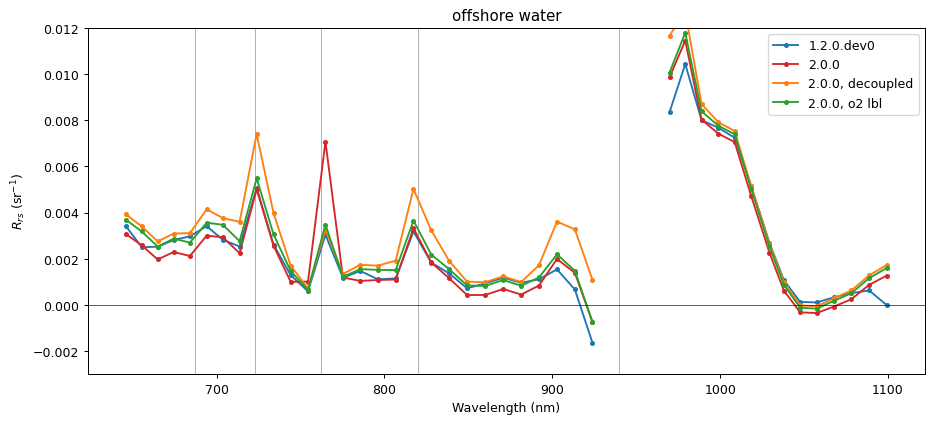

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))
for name in ['1.2.0.dev0', '2.0.0', '2.0.0, decoupled', '2.0.0, o2 lbl']:
    spectra[name].sel(wl=slice(640, 1100)).plot(ax=ax, color=colors[name], marker='.', label=name)
for label, wl in gas_bands.items():
    ax.axvline(wl, color='0.7', lw=0.8, zorder=0)
ax.axhline(0, color='k', lw=0.5)
ax.set(xlabel='Wavelength (nm)', ylabel='$R_{rs}$ (sr$^{-1}$)', ylim=(-0.003, 0.012), title='offshore water')
ax.legend();

## 5. Maps of the difference 2.0.0 - 1.2.0.dev0

At 560 nm, outside the gaseous bands, and at 765 nm, in the O2-A band.

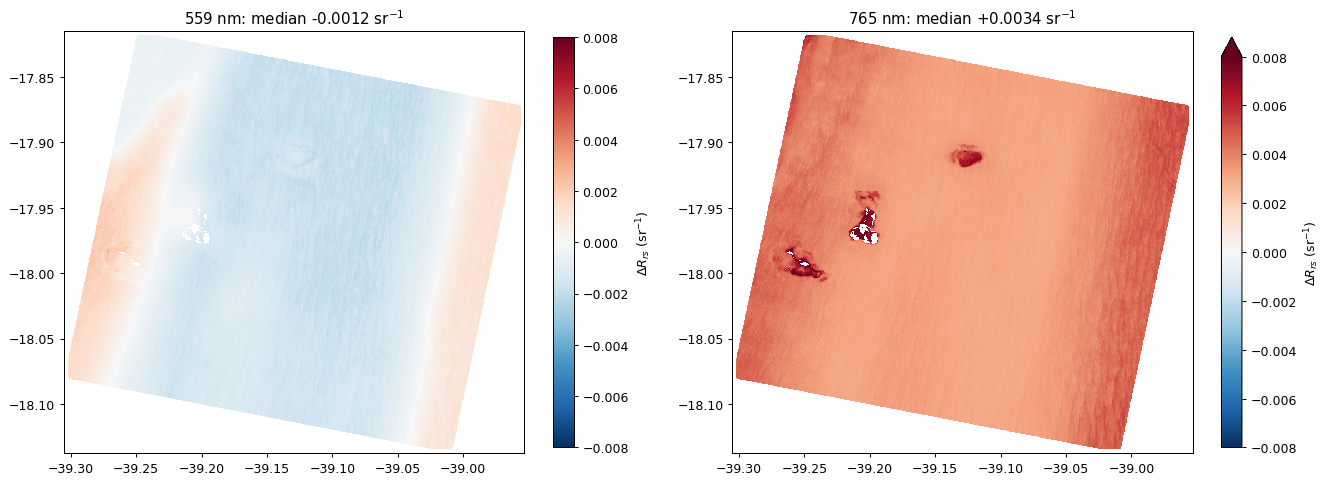

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, wl in zip(axs, [560, 765]):
    diff = products['2.0.0'].Rrs.sel(wl=wl, method='nearest') - products['1.2.0.dev0'].Rrs.sel(wl=wl, method='nearest')
    diff.plot.imshow(ax=ax, cmap='RdBu_r', vmin=-0.008, vmax=0.008,
                     cbar_kwargs={'label': r'$\Delta R_{rs}$ (sr$^{-1}$)', 'shrink': 0.8})
    ax.set(title=f'{float(diff.wl):.0f} nm: median {float(diff.median()):+.4f} sr$^{{-1}}$',
           xlabel='', ylabel='', aspect='equal')
plt.tight_layout()

## 6. Summary

There is no in situ measurement on this image: the comparison rests on the smoothness of $R_{rs}$ of clear
water across the gaseous bands and on CAMS. On this PRISMA image, 2.0.0 is not a clear improvement.

**Better in 2.0.0**

* O2-B band (687 nm): no residual (-0.3e-4 sr$^{-1}$ offshore, against -4e-4 and +4e-4 for 1.1.2 and
  1.2.0.dev0), from the line-by-line O2 absorption.
* Water vapor: 27.0 kg m$^{-2}$, closer to CAMS (32.7) than 1.1.2 (23.3) and 1.2.0.dev0 (22.2).
* Near infrared of clear water: $R_{rs}(865)$ = 0.0004 sr$^{-1}$ offshore, against 0.0009; the dip at
  924 nm (H2O 940) is smaller.
* H2O bands at 720 and 820 nm: the coupling helps, without it the peaks grow from +21e-4 to +32e-4 and from
  +18e-4 to +28e-4 sr$^{-1}$.

**Worse in 2.0.0**

* O2-A band (765 nm): a peak of +60e-4 sr$^{-1}$ offshore, about 6 times $R_{rs}$ of the shoulders (+17e-4
  for 1.2.0.dev0, -20e-4 for 1.1.2). It comes from the coupling combined with the REPTRAN O2 absorption of
  the O2-A band: with `gas_coupling: decoupled` or with `o2_model: lbl` (line by line in the O2-A band too) the
  peak falls back to +16e-4 / +20e-4, the level of 1.2.0.dev0.
* The aerosol optical thickness and the water vapor show along-track stripes in the maps, and $R_{rs}$ at 560 nm
  changes with the cross-track position (from -0.002 to +0.002 sr$^{-1}$ compared with 1.2.0.dev0).
* The AOT depends on the O2-A setting: 0.089 with the defaults, 0.15 with either variant (CAMS: 0.064).

**Unchanged**

* The peaks at 724 and 817 nm (H2O) of 1.2.0.dev0 (+20e-4, +16e-4 sr$^{-1}$; 1.1.2: +2e-4, +4e-4) remain.
* $R_{rs}$ is 0.007-0.011 sr$^{-1}$ at 970-1010 nm in all versions, where clear water is black: this is not
  water signal, and its source (detector overlap, sunglint residual) is not identified here.

For PRISMA, `o2_model: lbl` removes the O2-A peak and keeps the gain of the coupling in the H2O bands and the
O2-B band; the stripes and the 970-1010 nm residual need their own study.